# 01 · Exploração dos dados

Fase 2 do [`docs/workflow.md`](../docs/workflow.md): perceber os dados antes de treinar.
Os resultados e as decisões que saem daqui estão escritos em [`docs/qualidade_dados.md`](../docs/qualidade_dados.md).

## Como ler este notebook

Cada medição tem quatro partes:

1. **Pergunta**: o que queremos saber dos dados.
2. **Porque importa**: o que muda no modelo conforme a resposta.
3. **Código e resultado.**
4. **Como ler**: o que seria um resultado bom, mau ou estranho, e o que decidimos.

## Como correr

- No VS Code: abrir este ficheiro, escolher o kernel do `.venv` (canto superior direito) e carregar em "Run All".
- No terminal: `.venv/bin/jupyter nbconvert --to notebook --execute --inplace notebooks/01_exploracao.ipynb`

Corre sempre de cima para baixo. Se os números mudarem depois de atualizar os dados, é preciso atualizar também o `qualidade_dados.md`.

## Regra principal: não espreitar o teste

Os contratos publicados em novembro e dezembro de 2025 são o **teste** e não entram aqui. A exploração usa só o **treino** (janeiro a setembro de 2025). A **validação** (outubro de 2025) só aparece na secção 10, para ver quantos contratos novos ficariam cobertos.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
import cpv_data as cd

pd.set_option("display.max_colwidth", 90)

# Estilo dos gráficos: fundo claro, eixos discretos, uma cor por série
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#3d3d3a",
    "xtick.color": "#3d3d3a", "ytick.color": "#3d3d3a",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e1", "grid.linewidth": 0.8,
    "font.size": 11,
})
AZUL, LARANJA = "#2a78d6", "#eb6834"

## Preparação

Carregar os contratos e aplicar as decisões 1 a 3 do `qualidade_dados.md`:

1. só os publicados em 2025;
2. sem os 3 contratos sem CPV;
3. uma só cópia de cada `idcontrato`.

In [2]:
cols = ["objectoContrato", "descContrato", "CPV", "adjudicante", "DescrAcordoQuadro"]
raw = cd.load_contracts(cols)
raw["periodo"] = cd.period(raw["data"])

df = (raw[raw["periodo"].notna()]
      .dropna(subset=["CPV"])
      .drop_duplicates("idcontrato"))
df["codigo"] = cd.first_code(df["CPV"])
df = df.dropna(subset=["codigo"])
df["nivel"] = cd.code_level(df["codigo"])

print("Contratos publicados em 2025, depois das decisões 1 a 3:", len(df))
print(df["periodo"].value_counts().to_string())

Contratos publicados em 2025, depois das decisões 1 a 3: 224805
periodo
treino       166112
teste         36083
validação     22610


A partir daqui só se usa `treino`. A verificação abaixo **para o notebook com um erro** se algum contrato de teste lá entrar. Chama-se a isto uma verificação automática: se alguém mudar o código mais acima por engano, o erro aparece logo, em vez de passar despercebido.

In [3]:
treino = df[df["periodo"] == "treino"].copy()
validacao = df[df["periodo"] == "validação"].copy()

assert treino["data"].max() < cd.VAL_START, "Há contratos de validação ou teste no treino"
assert (df["periodo"] == "teste").sum() > 0  # o teste existe, mas não é usado daqui para baixo
del df  # para não o usar por engano

print("Treino:", len(treino), "contratos, de", treino["data"].min().date(), "a", treino["data"].max().date())

Treino: 166112 contratos, de 2025-01-01 a 2025-09-30


## Colunas: como são os dados

**Pergunta:** que colunas existem, quão preenchidas estão e que valores têm?

**Porque importa:** é o ponto de partida para decidir que colunas podem entrar no modelo. A descrição de cada coluna, e se existe quando o técnico escolhe o CPV, está em [`docs/dados.md`](../docs/dados.md).

Os valores mais comuns ficam cortados a 50 caracteres.

In [4]:
todas = pd.read_parquet(cd.RAW_PARQUET / "contratos2025.parquet").columns.tolist()
cols_treino = cd.load_contracts(todas)
cols_treino = cols_treino[cd.period(cols_treino["data"]) == "treino"].drop_duplicates("idcontrato")
print("Contratos de treino (antes de tirar os sem CPV):", len(cols_treino))

linhas = []
for c in todas:
    s = cols_treino[c]
    cheio = s.notna() & (s.str.strip() != "")
    vals = s[cheio].str.replace(r"\s+", " ", regex=True).str.strip()
    top = vals.value_counts().head(3)
    linhas.append({
        "coluna": c,
        "preenchida": cheio.mean(),
        "valores distintos": vals.nunique(),
        "valores mais comuns": "; ".join(f"{v[:50]} ({k})" for v, k in top.items()),
    })
del cols_treino
pd.set_option("display.max_rows", 50)
pd.DataFrame(linhas).set_index("coluna").style.format({"preenchida": "{:.1%}", "valores distintos": "{:,}"})

Contratos de treino (antes de tirar os sem CPV): 166113


,preenchida,valores distintos,valores mais comuns
coluna,,,
idcontrato,100.0%,"166,113",11757625 (1); 11757087 (1); 11757101 (1)
nAnuncio,15.9%,"15,871",2108/2025 (182); 24609/2024 (58); 8875/2025 (50)
TipoAnuncio,15.9%,5,Anúncio de procedimento (22681); Anúncio de Alteração (2918); Anúncio de concurso urgente (691)
idINCM,15.9%,"15,764",-1 (191); 418613422 (182); 418353129 (58)
tipoContrato,100.0%,28,Aquisição de bens móveis (82747); Aquisição de serviços (68342); Empreitadas de obras públicas (11204)
idprocedimento,100.0%,"131,499",7474261 (444); 7468015 (397); 7462678 (395)
tipoprocedimento,100.0%,17,Ajuste Direto Regime Geral (75458); Consulta Prévia (29713); Concurso público (26090)
objectoContrato,100.0%,"120,004",Medicamentos (1438); Aquisição de serviço de viagens e alojamento – Pla (633); Convite à apresentação de propostas ao abrigo do(s (423)
descContrato,100.0%,"121,491",Medicamentos (1419); Consulta Prévia ao abrigo do acordo-quadro da ESPA (914); Aquisição de serviço de viagens e alojamento – Pla (633)


**Como ler:**
- Uma coluna quase vazia (por exemplo `Observacoes`, 3,6%) dificilmente ajuda o modelo.
- Uma coluna com um só valor (`Ano`) não traz informação nenhuma.
- Colunas com informação que só existe depois da adjudicação (o vencedor, os concorrentes, o preço final) não podem entrar, mesmo que estejam cheias: seria fuga de dados.

## 7. Colunas que ajudam os textos vagos

**Pergunta:** quando o `objectoContrato` não diz o que se compra, há outras colunas que digam?

**Porque importa:** um texto como "convite à apresentação de propostas ao abrigo do acordo-quadro..." não dá ao modelo nenhuma pista. Se outra coluna tiver a informação, juntamo-la ao texto de entrada. Só vale a pena com colunas que o técnico já conhece quando escolhe o código, senão é fuga de dados.

In [5]:
preenchido = lambda s: s.notna() & (s.str.strip() != "")
texto = cd.normalize_text(treino["objectoContrato"])
fala_de_aq = texto.str.contains("acordo") & texto.str.contains("quadro")

pd.DataFrame({
    "% preenchido em todos os contratos": [preenchido(treino[c]).mean() for c in ["DescrAcordoQuadro", "adjudicante"]],
    "% preenchido nos que falam de acordo-quadro": [preenchido(treino.loc[fala_de_aq, c]).mean() for c in ["DescrAcordoQuadro", "adjudicante"]],
}, index=["DescrAcordoQuadro", "adjudicante"]).style.format("{:.1%}")

,% preenchido em todos os contratos,% preenchido nos que falam de acordo-quadro
DescrAcordoQuadro,15.5%,97.7%
adjudicante,100.0%,100.0%


In [6]:
print("Contratos que falam de acordo-quadro:", fala_de_aq.sum(), f"({fala_de_aq.mean():.1%} do treino)")
print()
print("Descrições de acordo-quadro mais comuns:")
treino.loc[fala_de_aq, "DescrAcordoQuadro"].str[:100].value_counts().head(5)

Contratos que falam de acordo-quadro: 9981 (6.0% do treino)

Descrições de acordo-quadro mais comuns:


DescrAcordoQuadro
961/2024 - Concurso público internacional para formação do acordo quadro de medicamentos diversos na    1503
491/2023 - Concurso público internacional para formação do acordo quadro de medicamentos do foro onc    1371
671/2023 - Concurso público internacional para formação do acordo quadro de medicamentos diversos        886
438/2023 - Acordo-quadro para fornecimento de derivados do plasma humano                                 460
780/2024 - Concurso público internacional para formação do acordo-quadro de medicamentos do aparelho     341
Name: count, dtype: int64

**Como ler:**
- A `DescrAcordoQuadro` está quase sempre preenchida quando o texto fala de acordo-quadro, e as descrições dizem o que se compra ("...acordo quadro de medicamentos..."). Resultado bom: resolve parte dos textos vagos.
- Um resultado mau seria a coluna estar vazia nesses contratos, ou repetir o mesmo texto vago.
- **Decisão 5:** juntar a `DescrAcordoQuadro` ao texto de entrada sempre que existir. **Decisão 7:** a `adjudicante` entra só como experiência (com e sem).

## 8. O mesmo texto com códigos diferentes

**Pergunta:** quando o mesmo texto aparece várias vezes, tem sempre o mesmo código?

**Porque importa:** se não tiver, o modelo vê a mesma pergunta com respostas diferentes. Temos de decidir que resposta fica, e saber quantos contratos isso afeta.

Exemplo concreto, o texto mais repetido:

In [7]:
treino["texto"] = cd.normalize_text(treino["objectoContrato"])
med = treino[treino["texto"] == "medicamentos"]
print(f"'medicamentos': {len(med)} contratos, {med['adjudicante'].nunique()} entidades")
med["CPV"].str[:80].value_counts().to_frame("contratos")

'medicamentos': 1565 contratos, 7 entidades


,contratos
CPV,
"33000000-0 - Equipamento médico, medicamentos e produtos para cuidados pessoais",1457
33600000-6 - Produtos farmacêuticos,105
33690000-3 - Medicamentos vários,2
"32000000-3 - Equipamento de rádio, televisão, comunicação, telecomunicações e af",1


In [8]:
por_par = treino.groupby(["texto", "codigo"]).size().rename("n").reset_index()
por_texto = por_par.groupby("texto")["n"]
fora_do_mais_comum = (por_texto.sum() - por_texto.max()).sum()
textos_em_conflito = (por_par.groupby("texto")["codigo"].nunique() > 1).sum()

print("Textos com mais do que um código:", textos_em_conflito)
print(f"Contratos com um código diferente do mais comum do seu texto: {fora_do_mais_comum} ({fora_do_mais_comum / len(treino):.1%})")

Textos com mais do que um código: 1700
Contratos com um código diferente do mais comum do seu texto: 3585 (2.2%)


**Como ler:**
- Em "medicamentos" quase todos os contratos têm o mesmo código. Os outros são poucos.
- A percentagem de contratos fora do código mais comum é o que se perde se ficarmos só com esse código. Resultado bom: poucos por cento. Resultado mau: dezenas por cento, o que quereria dizer que o texto sozinho não chega para decidir.
- **Decisão 6:** no treino, um só exemplo por texto, com o código mais comum desse texto.
- Este número usa só o `objectoContrato`. Com o texto de entrada completo (decisão 5) deve ser um pouco menor; volta a medir-se na preparação.

## 9. A que nível da árvore as entidades escolhem o código

**Pergunta:** quantos contratos têm um código genérico (por exemplo `33000000`, ao nível da divisão) em vez de um específico?

**Porque importa:** o objetivo é sugerir códigos específicos. Se o modelo aprender com etiquetas genéricas, vai sugerir códigos genéricos, que é o erro que queremos evitar.

O nível conta-se pelos dígitos antes dos zeros finais: `33600000` → `336` → 3 dígitos → grupo. É uma aproximação.

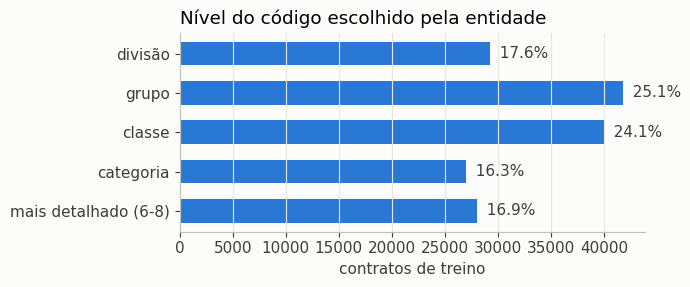

,contratos,pct
nivel,,
divisão,29281,17.6%
grupo,41737,25.1%
classe,40029,24.1%
categoria,26997,16.3%
mais detalhado (6-8),28068,16.9%


In [9]:
niveis = cd.level_name(treino["nivel"]).value_counts()
ordem = ["divisão", "grupo", "classe", "categoria", "mais detalhado (6-8)"]
niveis = niveis.reindex(ordem)

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(niveis.index[::-1], niveis.values[::-1], color=AZUL, height=0.6)
for y, v in enumerate(niveis.values[::-1]):
    ax.text(v, y, f"  {v / len(treino):.1%}", va="center", color="#3d3d3a")
ax.set_xlabel("contratos de treino")
ax.set_title("Nível do código escolhido pela entidade", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

niveis.to_frame("contratos").assign(pct=lambda t: t["contratos"] / len(treino)).style.format({"pct": "{:.1%}"})

In [10]:
treino["divisao"] = treino["codigo"].str[:2]
por_div = treino.groupby("divisao").agg(
    contratos=("codigo", "size"),
    pct_nivel_divisao=("nivel", lambda s: (s == 2).mean()),
    pct_ate_grupo=("nivel", lambda s: (s <= 3).mean()),
    ficam_sem_divisao=("nivel", lambda s: (s > 2).sum()),
).sort_values("contratos", ascending=False)
print("As 10 divisões com mais contratos:")
por_div.head(10).style.format({"pct_nivel_divisao": "{:.1%}", "pct_ate_grupo": "{:.1%}"})

As 10 divisões com mais contratos:


,contratos,pct_nivel_divisao,pct_ate_grupo,ficam_sem_divisao
divisao,,,,
33,50405,26.2%,70.3%,37213
45,11298,9.4%,15.2%,10235
79,10534,6.3%,19.2%,9874
92,7808,18.9%,31.6%,6330
50,7267,32.4%,50.7%,4915
71,6755,9.2%,24.6%,6134
72,5811,15.7%,39.2%,4897
85,4488,20.5%,39.6%,3566
15,4355,15.8%,53.9%,3666


In [11]:
print("Divisão que fica com menos contratos se tirarmos os códigos ao nível da divisão:")
por_div.sort_values("ficam_sem_divisao").head(3)

Divisão que fica com menos contratos se tirarmos os códigos ao nível da divisão:


,contratos,pct_nivel_divisao,pct_ate_grupo,ficam_sem_divisao
divisao,,,,
41,28,0.750000,0.857143,7
76,52,0.519231,0.634615,25
70,71,0.098592,0.281690,64


**Como ler:**
- Se os genéricos fossem poucos (por exemplo 2%), podíamos ignorá-los. São muitos: quase 1 em cada 5 contratos está ao nível da divisão.
- A divisão `33` é a maior e uma das mais afetadas.
- Um resultado mau seria tirar os genéricos e uma divisão ficar sem contratos. Não acontece: a pior fica com poucos, mas já era muito pequena.
- Genérico não é o mesmo que errado: às vezes o código geral é a escolha certa.
- **Decisão 8:** no treino, tirar só os códigos ao nível da divisão. Na avaliação, avaliar cada contrato só até ao nível que a etiqueta tem.

## 10. Quantos exemplos tem cada código (desequilíbrio de classes)

**Pergunta:** depois da decisão 8, quantos códigos distintos ficam, e quantos exemplos tem cada um?

**Porque importa:** um modelo não aprende um código com 1 ou 2 exemplos. Temos de decidir um número mínimo de exemplos (N) para um código entrar no treino. Quanto maior o N, menos códigos o modelo conhece e mais contratos ficam de fora.

In [12]:
treino_esp = treino[treino["nivel"] > 2]
validacao_esp = validacao[validacao["nivel"] > 2]
print("Treino sem códigos ao nível da divisão:", len(treino_esp))
print("Validação sem códigos ao nível da divisão:", len(validacao_esp))

pd.Series({
    "divisão (2)": treino_esp["codigo"].str[:2].nunique(),
    "grupo (3)": treino_esp["codigo"].str[:3].nunique(),
    "classe (4)": treino_esp["codigo"].str[:4].nunique(),
    "código como foi escolhido (8)": treino_esp["codigo"].nunique(),
}).to_frame("códigos distintos no treino")

Treino sem códigos ao nível da divisão: 136831
Validação sem códigos ao nível da divisão: 18718


,códigos distintos no treino
divisão (2),45
grupo (3),260
classe (4),1013
código como foi escolhido (8),4330


Mediana de exemplos por código: 4
Códigos com 1 só exemplo: 1103
Código mais comum: 33600000 com 18987 exemplos (13.9% do treino)
Os 10 códigos mais comuns cobrem 28.0% do treino


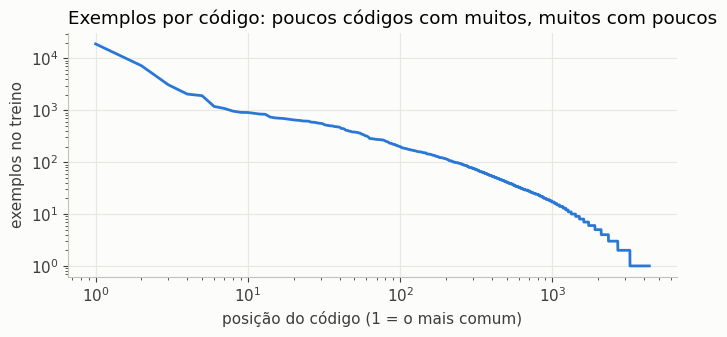

In [13]:
vc = treino_esp["codigo"].value_counts()
print("Mediana de exemplos por código:", int(vc.median()))
print("Códigos com 1 só exemplo:", (vc == 1).sum())
print(f"Código mais comum: {vc.index[0]} com {vc.iloc[0]} exemplos ({vc.iloc[0] / len(treino_esp):.1%} do treino)")
print(f"Os 10 códigos mais comuns cobrem {vc.head(10).sum() / len(treino_esp):.1%} do treino")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(1, len(vc) + 1), vc.values, color=AZUL, linewidth=2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("posição do código (1 = o mais comum)")
ax.set_ylabel("exemplos no treino")
ax.set_title("Exemplos por código: poucos códigos com muitos, muitos com poucos", loc="left")
plt.tight_layout()
plt.show()

O gráfico usa escala logarítmica nos dois eixos: cada risca vale 10 vezes a anterior. Sem isso, os códigos com milhares de exemplos esmagavam o resto e não se via nada.

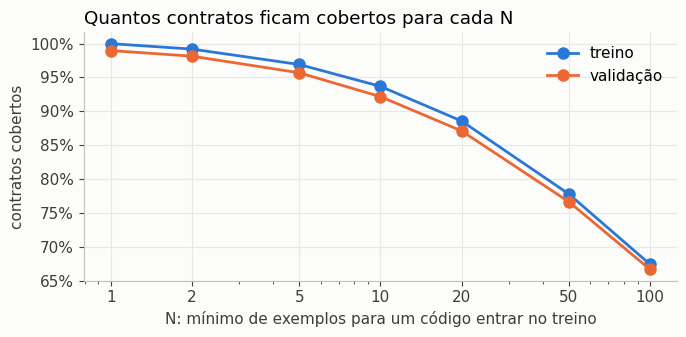

,códigos que ficam,% contratos de treino,% contratos de validação
N (mínimo de exemplos),,,
1,4330,100.0%,99.0%
2,3227,99.2%,98.1%
5,2089,96.9%,95.7%
10,1418,93.7%,92.2%
20,911,88.6%,87.1%
50,431,77.8%,76.6%
100,229,67.4%,66.6%


In [14]:
linhas = []
for n in [1, 2, 5, 10, 20, 50, 100]:
    ficam = vc[vc >= n].index
    linhas.append({
        "N (mínimo de exemplos)": n,
        "códigos que ficam": len(ficam),
        "% contratos de treino": treino_esp["codigo"].isin(ficam).mean(),
        "% contratos de validação": validacao_esp["codigo"].isin(ficam).mean(),
    })
cobertura = pd.DataFrame(linhas).set_index("N (mínimo de exemplos)")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cobertura.index, cobertura["% contratos de treino"], color=AZUL, linewidth=2, marker="o", markersize=8, label="treino")
ax.plot(cobertura.index, cobertura["% contratos de validação"], color=LARANJA, linewidth=2, marker="o", markersize=8, label="validação")
ax.set_xscale("log")
ax.set_xticks(cobertura.index, [str(n) for n in cobertura.index])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("N: mínimo de exemplos para um código entrar no treino")
ax.set_ylabel("contratos cobertos")
ax.set_title("Quantos contratos ficam cobertos para cada N", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

cobertura.style.format({"% contratos de treino": "{:.1%}", "% contratos de validação": "{:.1%}"})

**Como ler:**
- **Desequilíbrio de classes:** metade dos códigos tem poucos exemplos, e um só código tem uma fatia grande do treino. É por isto que vamos medir o F1 macro: com ele, um modelo que só acerta nos códigos comuns tem nota baixa.
- **"% contratos de validação"** responde a: dos contratos novos (outubro), quantos têm um código que o modelo conhece? É uma estimativa do teto. Um contrato cujo código o modelo não conhece nunca vai ser acertado no código completo.
- As duas curvas quase coincidem. Isso é bom: o treino representa bem os meses seguintes. Se a validação estivesse muito abaixo do treino, quereria dizer que os códigos mudam muito de mês para mês.
- **Por decidir na fase 3:** o valor de N, e o que fazer com os contratos cujo código fica de fora (por exemplo, subir para o código da classe).

## Como avaliar este notebook

Perguntas para fazer a qualquer exploração, esta ou outra:

1. **Os números vêm do código?** Cada número do `qualidade_dados.md` tem de sair de uma célula deste notebook ou do `00_qualidade.ipynb`. Se não sair, não está verificado.
2. **Corre de cima para baixo sem erros?** "Run All" num kernel novo. Se só funciona correndo as células noutra ordem, está errado.
3. **Usa só os dados que deve?** Procurar onde se filtra o período. Aqui: a célula com o `assert` garante que o teste não entra.
4. **Os números fazem sentido?** As percentagens somam 100%? Os totais batem com os de outras secções? Um número muito bom ou muito mau merece desconfiança antes de festejo.
5. **Cada medição leva a uma decisão?** Se uma medição não muda nada no que vamos fazer, é curiosidade, não exploração.
6. **As decisões estão escritas?** Aqui, no `qualidade_dados.md`. Daqui a um mês ninguém se lembra porque se tirou os códigos ao nível da divisão.